#### Phase 1 - Data Preparation

Loads what `src/parse.py`, `src/prepare_yolo.py`, `src/prepare_recognition.py` and `src/augment.py` produced. Nothing is recomputed here.

Checks the bounding boxes, dataset splits, readings and augmentation.

In [1]:
import sys, ast, random
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from parse import parse_annotation, xywh_to_yolo, yolo_to_xywh
from augment import augment_image

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

#### 1. Split and camera counts (`results/data/dataset_details.csv`)


In [2]:
details_path = resolve_path(CONFIG["paths"]["dataset_details"])
df = pd.read_csv(details_path, dtype={"reading": str})
df["reading"] = df["reading"].str.zfill(5)
df["counter_bbox"] = df["counter_bbox"].apply(ast.literal_eval)
df["digit_bboxes"] = df["digit_bboxes"].apply(ast.literal_eval)

print(f"total rows: {len(df)}")
print(df["split"].value_counts())
assert dict(df["split"].value_counts()) == {"training": 800, "testing": 800, "validation": 400}, \
    "split counts do not match the UFPR-AMR distributed split (800/400/800)"
print("split counts OK (800/400/800)")


total rows: 2000
split
training      800
testing       800
validation    400
Name: count, dtype: int64
split counts OK (800/400/800)


In [3]:
print(df["camera"].value_counts())
df.head()


camera
LG G3 D855                 947
Samsung Galaxy J7 Prime    584
iPhone 6s                  469
Name: count, dtype: int64


,filename,split,camera,reading,counter_bbox,digit_bboxes,img_w,img_h,image_path,annotation_path
0,meter0001.jpg,training,LG G3 D855,00001,"(879, 1775, 434, 178)","[(888, 1788, 84, 146), (978, 1788, 76, 144), (...",2340,4160,data/raw/training/meter0001.jpg,data/raw/training/meter0001.txt
1,meter0002.jpg,training,LG G3 D855,00495,"(1078, 1788, 281, 103)","[(1084, 1795, 49, 92), (1138, 1795, 49, 91), (...",2340,4160,data/raw/training/meter0002.jpg,data/raw/training/meter0002.txt
2,meter0003.jpg,training,LG G3 D855,00447,"(887, 1596, 335, 140)","[(919, 1619, 52, 103), (975, 1621, 54, 98), (1...",2340,4160,data/raw/training/meter0003.jpg,data/raw/training/meter0003.txt
3,meter0004.jpg,training,LG G3 D855,12399,"(952, 2037, 272, 104)","[(956, 2046, 42, 92), (1002, 2043, 53, 93), (1...",2340,4160,data/raw/training/meter0004.jpg,data/raw/training/meter0004.txt
4,meter0005.jpg,training,LG G3 D855,00000,"(1013, 1744, 339, 148)","[(1025, 1771, 59, 106), (1091, 1776, 57, 101),...",2340,4160,data/raw/training/meter0005.jpg,data/raw/training/meter0005.txt


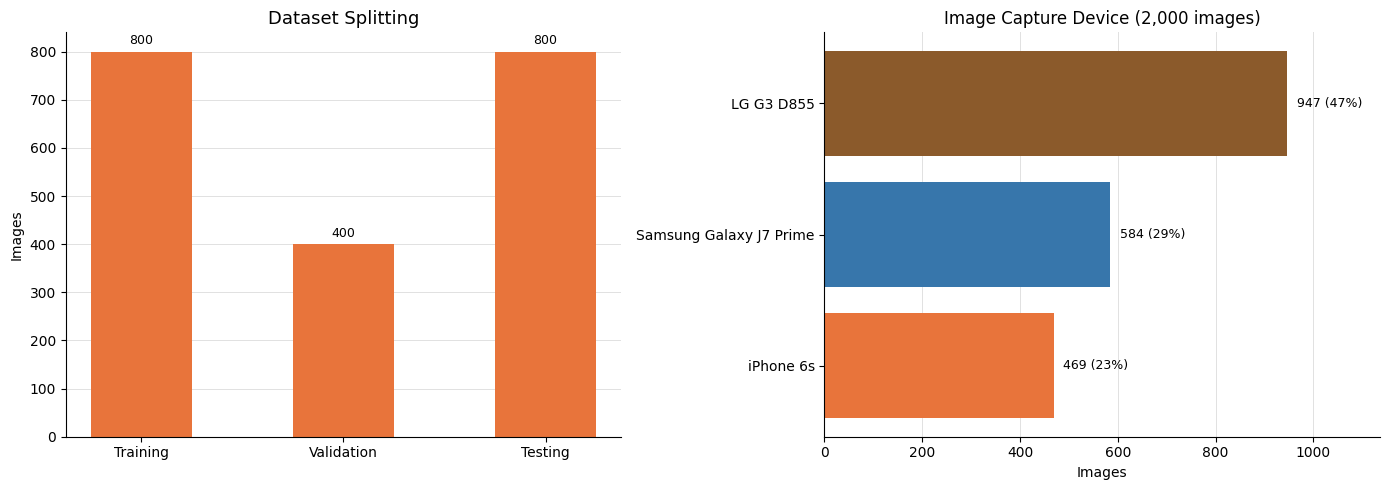

In [4]:
split_order = ["training", "validation", "testing"]
split_display = {"training": "Training", "validation": "Validation", "testing": "Testing"}
img_counts = [int((df["split"] == s).sum()) for s in split_order]

cam_counts = df["camera"].value_counts()
cam_total = cam_counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- left: split counts ---
ax = axes[0]
x = np.arange(len(split_order))
bars = ax.bar(x, img_counts, width=0.5, color="#E8743B")
ax.bar_label(bars, fontsize=9, padding=3)
ax.set_xticks(x); ax.set_xticklabels([split_display[s] for s in split_order])
ax.set_ylabel("Images")
ax.set_title("Dataset Splitting", fontsize=13)
ax.set_axisbelow(True)
ax.grid(axis="y", color="lightgray", linewidth=0.7, alpha=0.7)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

# --- right: capture device breakdown ---
ax = axes[1]
device_colors = ["#8B5A2B", "#3776ab", "#E8743B"]
labels = list(cam_counts.index)
values = list(cam_counts.values)
y = np.arange(len(labels))
bars = ax.barh(y, values, color=device_colors[:len(labels)])
for yi, v in zip(y, values):
    ax.text(v + cam_total * 0.01, yi, f"{v} ({v / cam_total * 100:.0f}%)",
            va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("Images")
ax.set_title(f"Image Capture Device ({cam_total:,} images)")
ax.set_xlim(0, max(values) * 1.2)
ax.set_axisbelow(True)
ax.grid(axis="x", color="lightgray", linewidth=0.7, alpha=0.7)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

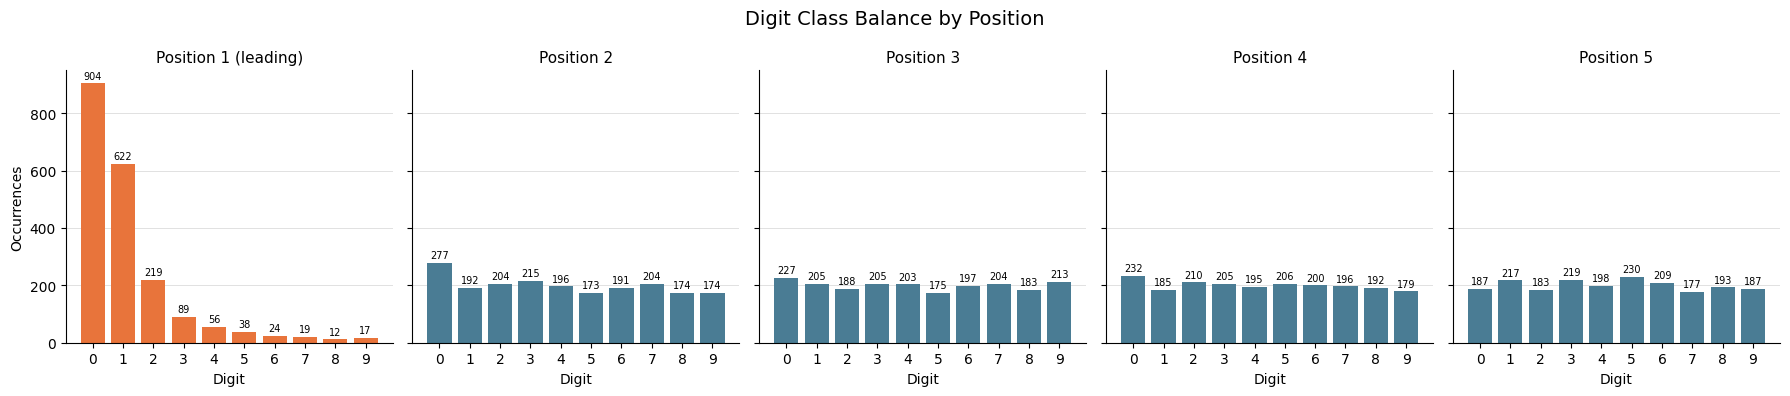

In [5]:
# Digit class balance by position: the first digit is mostly 0/1, positions 2-5 are
# balanced (Laroca et al., 2019, Fig. 2).
readings = df["reading"].astype(str).str.zfill(5)
digits_index = [str(d) for d in range(10)]

fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)
for pos in range(5):
    counts = readings.str[pos].value_counts().reindex(digits_index, fill_value=0)
    color = "#E8743B" if pos == 0 else "#4A7C94"
    ax = axes[pos]
    bars = ax.bar(digits_index, counts.values, color=color)
    ax.bar_label(bars, fontsize=7, padding=2)
    ax.set_title(f"Position {pos + 1}" + (" (leading)" if pos == 0 else ""), fontsize=11)
    ax.set_xlabel("Digit")
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="lightgray", linewidth=0.7, alpha=0.7)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
axes[0].set_ylabel("Occurrences")
fig.suptitle("Digit Class Balance by Position", fontsize=14)
fig.tight_layout()
plt.show()

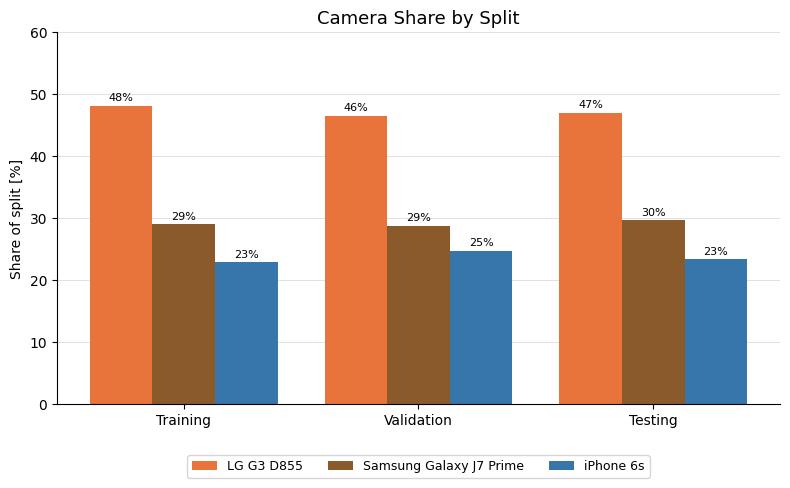

In [6]:
# Camera share within each split - confirms no camera bias between splits
ct = pd.crosstab(df["split"], df["camera"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
split_order = ["training", "validation", "testing"]
split_display = {"training": "Training", "validation": "Validation", "testing": "Testing"}
ct_pct = ct_pct.reindex(split_order)

cameras = list(ct_pct.columns)
device_colors = ["#E8743B", "#8B5A2B", "#3776ab"]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(split_order)); width = 0.8 / len(cameras)
for i, (cam, color) in enumerate(zip(cameras, device_colors)):
    offset = (i - (len(cameras) - 1) / 2) * width
    bars = ax.bar(x + offset, ct_pct[cam], width, label=cam, color=color)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8, padding=2)

ax.set_xticks(x); ax.set_xticklabels([split_display[s] for s in split_order])
ax.set_ylabel("Share of split [%]"); ax.set_ylim(0, 60)
ax.set_title("Camera Share by Split", fontsize=13)
ax.set_axisbelow(True)
ax.grid(axis="y", color="lightgray", linewidth=0.7, alpha=0.7)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9)
fig.tight_layout()
plt.show()

#### 2. Parsed readings vs. the source `.txt` files

20 random rows, re-parsed from the raw annotation and compared to the CSV.


In [7]:
sample = df.sample(20, random_state=CONFIG["seed"])

mismatches = []
for _, row in sample.iterrows():
    ann = parse_annotation(resolve_path(row["annotation_path"]))
    if ann["reading"] != row["reading"]:
        mismatches.append((row["filename"], ann["reading"], row["reading"]))

print(f"checked {len(sample)} readings against source .txt files")
if mismatches:
    print("MISMATCHES:", mismatches)
else:
    print("all 20 sampled readings match the source .txt files exactly, leading zeros intact")
assert not mismatches


checked 20 readings against source .txt files
all 20 sampled readings match the source .txt files exactly, leading zeros intact


#### 3. Bounding-box round trip (`xywh_to_yolo` → `yolo_to_xywh`)

The conversion must be lossless up to integer rounding.


In [8]:
sample = df.sample(50, random_state=CONFIG["seed"])

max_drift = 0
for _, row in sample.iterrows():
    boxes = [row["counter_bbox"]] + row["digit_bboxes"]
    for box in boxes:
        yolo_box = xywh_to_yolo(box, row["img_w"], row["img_h"])
        back = yolo_to_xywh(yolo_box, row["img_w"], row["img_h"])
        drift = max(abs(a - b) for a, b in zip(box, back))
        max_drift = max(max_drift, drift)

print(f"checked {len(sample) * 6} boxes (counter + 5 digits per image)")
print(f"max round-trip drift: {max_drift} px")
assert max_drift <= 1, "round-trip conversion drift exceeds integer rounding tolerance"
print("round-trip conversion OK")


checked 300 boxes (counter + 5 digits per image)
max round-trip drift: 0 px
round-trip conversion OK


#### 4. Bboxes drawn on 10 random raw images

Green = counter region, blue = digit boxes.


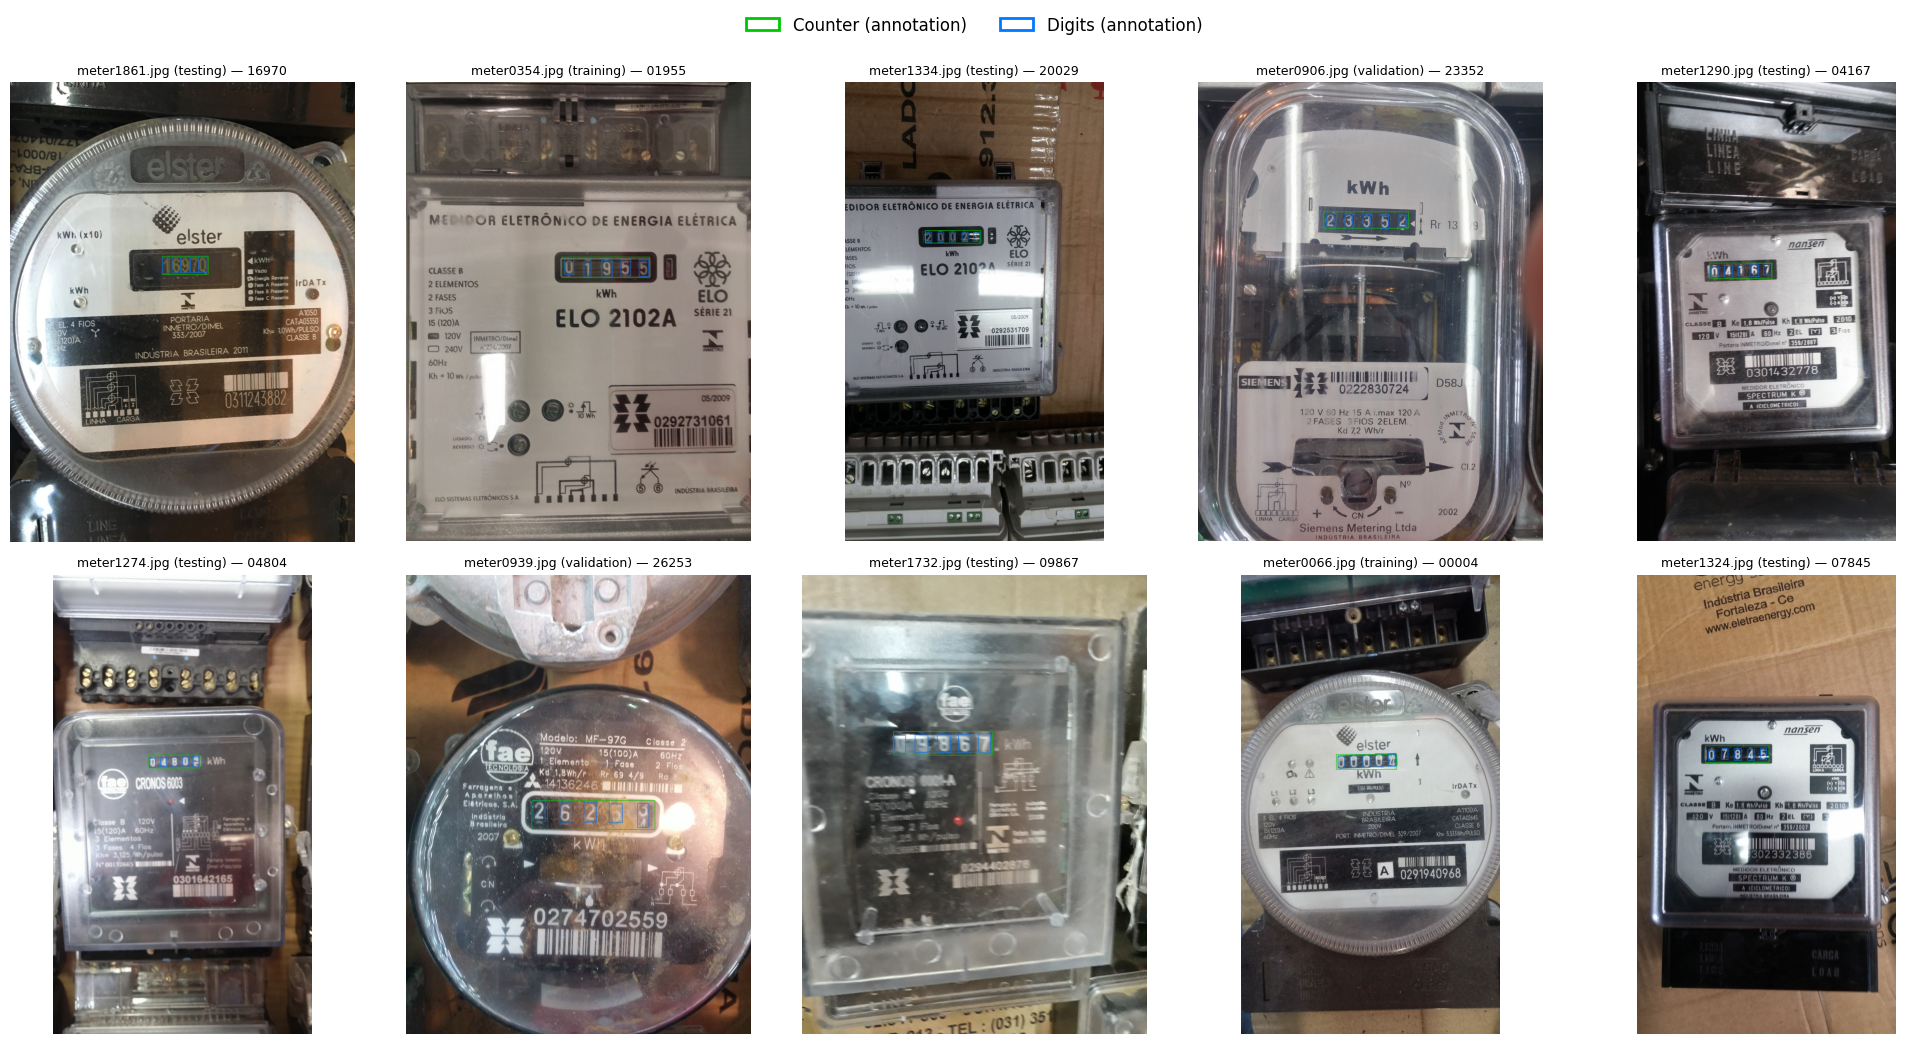

saved /Users/chuitinglum/Desktop/meter-reading/results/data/phase1_bbox_verification.png


In [9]:
sample = df.sample(10, random_state=CONFIG["seed"]).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = cv2.cvtColor(cv2.imread(str(resolve_path(row["image_path"]))), cv2.COLOR_BGR2RGB)
    x, y, w, h = row["counter_bbox"]
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 200, 0), 4)
    for dx, dy, dw, dh in row["digit_bboxes"]:
        cv2.rectangle(img, (dx, dy), (dx + dw, dy + dh), (0, 120, 255), 3)
    ax.imshow(img)
    ax.set_title(f"{row['filename']} ({row['split']}) - {row['reading']}", fontsize=9)
    ax.axis("off")

from matplotlib.patches import Patch
legend_boxes = [Patch(facecolor="none", edgecolor=np.array((0, 200, 0)) / 255, linewidth=2, label="Counter (annotation)"),
                Patch(facecolor="none", edgecolor=np.array((0, 120, 255)) / 255, linewidth=2, label="Digits (annotation)")]
plt.tight_layout()
fig.legend(handles=legend_boxes, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=12, frameon=False)
out_path = resolve_path(CONFIG["paths"]["bbox_verification"])
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=100, bbox_inches="tight")
plt.show()
print(f"saved {out_path}")


#### 5. YOLO label files

Labels written by `prepare_yolo.py` must decode back to the counter bbox in `dataset_details.csv`.


In [10]:
yolo_dir = resolve_path(CONFIG["paths"]["yolo_dir"])

sample = df.sample(15, random_state=CONFIG["seed"])
max_drift = 0
for _, row in sample.iterrows():
    stem = Path(row["filename"]).stem
    label_path = yolo_dir / row["split"] / "labels" / f"{stem}.txt"
    assert label_path.exists(), f"missing YOLO label for {row['filename']}"

    cls_id, cx, cy, w, h = (float(v) for v in label_path.read_text().split())
    assert int(cls_id) == 0

    back = yolo_to_xywh((cx, cy, w, h), row["img_w"], row["img_h"])
    drift = max(abs(a - b) for a, b in zip(row["counter_bbox"], back))
    max_drift = max(max_drift, drift)

print(f"checked {len(sample)} YOLO label files, max drift vs. dataset_details.csv: {max_drift} px")
assert max_drift <= 1
print("YOLO label files OK")


checked 15 YOLO label files, max drift vs. dataset_details.csv: 0 px
YOLO label files OK


#### 6. Recognition crops

Counter crop (400×106) and its five digit crops (32×32); the digit crops must read
left to right as the reading.


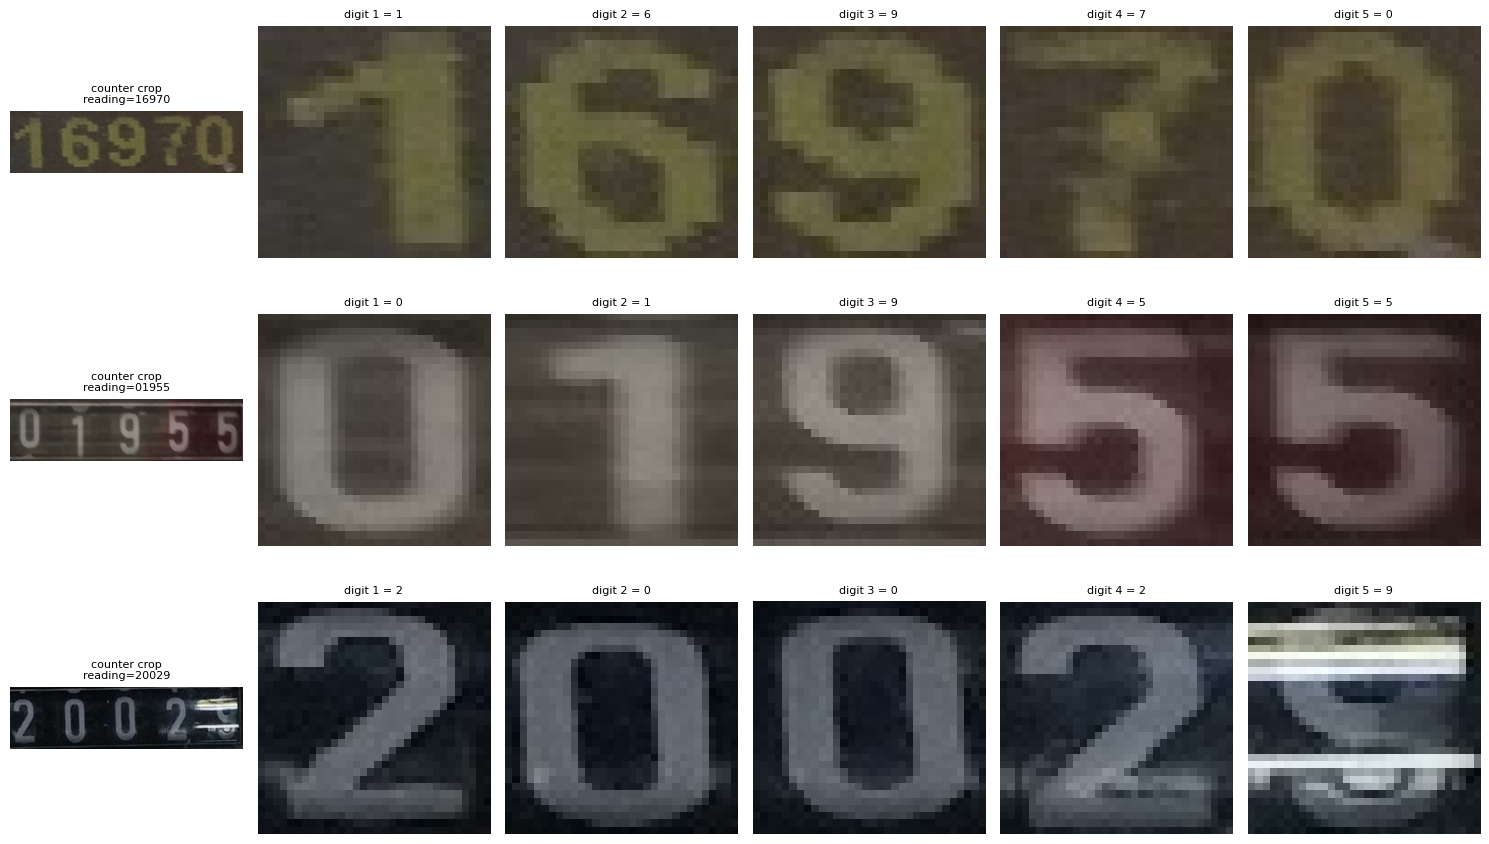

In [11]:
recog_dir = resolve_path(CONFIG["paths"]["recognition_dir"])
sample = df.sample(3, random_state=CONFIG["seed"])

fig, axes = plt.subplots(len(sample), 6, figsize=(15, 3 * len(sample)))
for row_i, (_, row) in enumerate(sample.iterrows()):
    stem = Path(row["filename"]).stem
    split_dir = recog_dir / row["split"]

    counter_img = cv2.cvtColor(cv2.imread(str(split_dir / "counters" / f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
    axes[row_i, 0].imshow(counter_img)
    axes[row_i, 0].set_title(f"counter crop\nreading={row['reading']}", fontsize=8)
    axes[row_i, 0].axis("off")

    for d in range(5):
        digit_label = row["reading"][d]
        digit_path = split_dir / "digits" / f"{stem}_d{d+1}_{digit_label}.jpg"
        assert digit_path.exists(), f"missing digit crop: {digit_path}"
        digit_img = cv2.cvtColor(cv2.imread(str(digit_path)), cv2.COLOR_BGR2RGB)
        axes[row_i, d + 1].imshow(digit_img)
        axes[row_i, d + 1].set_title(f"digit {d+1} = {digit_label}", fontsize=8)
        axes[row_i, d + 1].axis("off")

plt.tight_layout()
plt.show()


#### 7. Augmentation (`src/augment.py`, training split only)


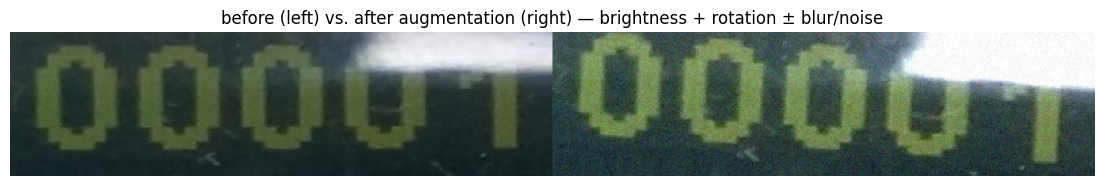

In [12]:
aug_path = resolve_path(CONFIG["paths"]["augment_demo"])
if aug_path.exists():
    img = cv2.cvtColor(cv2.imread(str(aug_path)), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(14, 4))
    plt.imshow(img)
    plt.title("before (left) vs. after augmentation (right) - brightness + rotation ± blur/noise")
    plt.axis("off")
    plt.show()
else:
    print(f"{aug_path} not found - run `python src/augment.py` first")


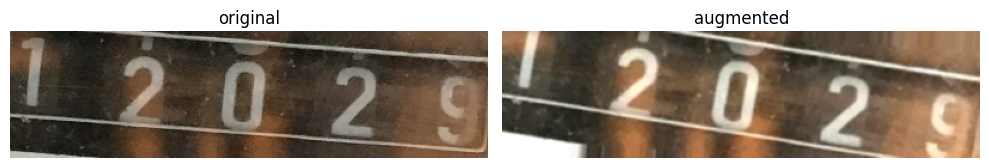

In [13]:
# any image works; the path is relative to the project root
img = cv2.imread(str(resolve_path("data/recognition/training/counters/meter0789.jpg")))
assert img is not None, "image not found"
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, im, title in zip(axes, (img, augment_image(img)), ("original", "augmented")):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()